# 02 · Preprocessing and Information Extraction

**Use Case 3: Research Paper Analysis and Recommendation System**  
**Owner:** Member A (data & extraction lead)

**Goal:** Build the shared text-preprocessing pipeline and pull structured information (key phrases, methods, datasets, authors) out of the abstracts.

**Basic techniques (Weeks 1–6)**
- Text preprocessing: tokenisation, normalisation, lemmatisation, stop-word removal (spaCy / NLTK)
- POS tagging: key-phrase candidates from `ADJ* NOUN+` patterns
- NER + rule-based extraction: spaCy NER plus regex for method/dataset names (e.g. `BERT`, `ImageNet`), years and acronyms

**Advanced techniques (Weeks 7–12)**
- Few-shot LLM extraction (W9 prompting, 3 worked examples), with a zero-shot ablation
- Hybrid ensemble: few-shot LLM + regex rules
- Hallucination / format check of the LLM output (W10): share of names that occur in the abstract, valid-JSON rate

**Evaluation:** 20 hand-labelled test abstracts; micro P/R/F1 for five extractors (regex, spaCy NER, zero-shot LLM, few-shot LLM, hybrid), per-field scores and an error analysis.

**Report section:** Introduction; dataset and preprocessing; basic extraction (~1,000 words).

## Setup

Run `01_data_loading_and_sampling.ipynb` first. Always evaluate on `test_df`.

In [1]:
from utils import load_sample, load_split

df = load_sample()
train_df, test_df = load_split(df)
print(f"all={len(df):,}  train={len(train_df):,}  test={len(test_df):,}")
train_df[["id", "primary_category", "title"]].head()

all=12,000  train=9,600  test=2,400


,id,primary_category,title
0,2404.00934,cs.CL,ChatGLM-RLHF: Practices of Aligning Large Lang...
1,2304.01712,cs.CL,Rumour Detection and Analysis on Twitter
2,2509.24120,cs.CL,EduVidQA: Generating and Evaluating Long-form ...
3,1706.03747,cs.CL,Acoustic data-driven lexicon learning based on...
4,1805.04793,cs.CL,Coarse-to-Fine Decoding for Neural Semantic Pa...


In [2]:
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.stem import PorterStemmer
from spacy.lang.en.stop_words import STOP_WORDS
from wordcloud import WordCloud

import extraction as ex
from utils import save_results, ARTIFACTS_DIR

SEED = 42
CATEGORIES = sorted(df["primary_category"].unique())
results = {}          # every headline number goes in here; saved at the end with save_results("02", ...)
print(CATEGORIES)

['cs.AI', 'cs.CL', 'cs.CR', 'cs.CV', 'cs.IR', 'cs.LG']


## Corpus statistics (W1)

Week 1 text statistics on the whole 12k sample, split by research domain: number of papers, average abstract length, vocabulary size and vocabulary richness (type-token ratio = unique words / total words). Tokenisation here is the simple Week 1 approach (lowercase, letters only) so the numbers describe the raw text before any preprocessing.

In [3]:
def simple_words(text):
    """Week 1 style tokenisation: lowercase and keep runs of letters."""
    return re.findall(r"[a-z]+", text.lower())


rows = []
for category in CATEGORIES:
    texts = df.loc[df["primary_category"] == category, "abstract"]
    all_words = []
    lengths = []
    for text in texts:
        words = simple_words(text)
        all_words.extend(words)
        lengths.append(len(words))
    rows.append({
        "category": category,
        "papers": len(texts),
        "mean_words": round(np.mean(lengths), 1),
        "vocab_size": len(set(all_words)),
        "type_token_ratio": round(len(set(all_words)) / len(all_words), 4),
    })

corpus_stats = pd.DataFrame(rows).set_index("category")
results["corpus_stats"] = corpus_stats.reset_index().to_dict(orient="records")
corpus_stats

,papers,mean_words,vocab_size,type_token_ratio
category,,,,
cs.AI,2000,178.8,15258,0.0427
cs.CL,2000,168.6,13824,0.0410
cs.CR,2000,181.8,15245,0.0419
cs.CV,2000,187.2,14714,0.0393
cs.IR,2000,184.8,13308,0.0360
cs.LG,2000,182.6,14251,0.0390


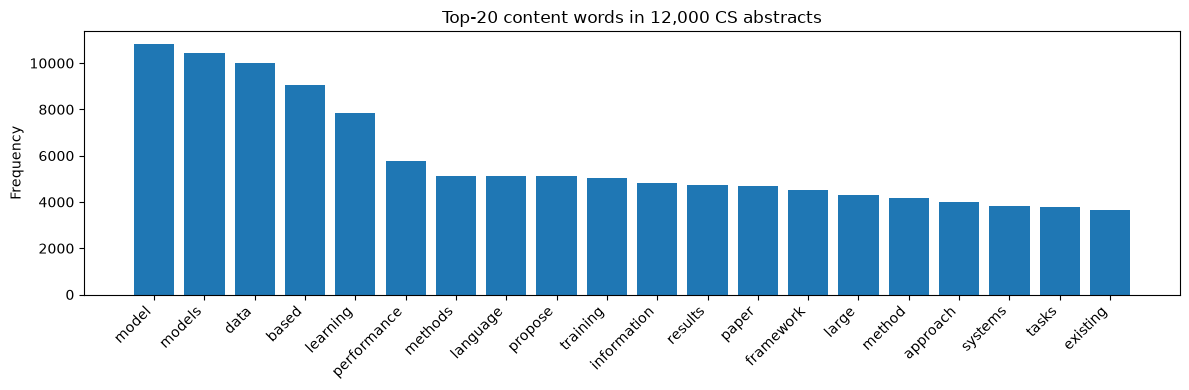

In [4]:
# Top-20 content words over the whole sample (stop-words removed), Week 1 frequency plot
word_counts = Counter()
for text in df["abstract"]:
    for word in simple_words(text):
        if word not in STOP_WORDS and len(word) > 2:
            word_counts[word] += 1

top20 = word_counts.most_common(20)
plt.figure(figsize=(12, 4))
plt.bar([w for w, c in top20], [c for w, c in top20])
plt.xticks(rotation=45, ha="right")
plt.title("Top-20 content words in 12,000 CS abstracts")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

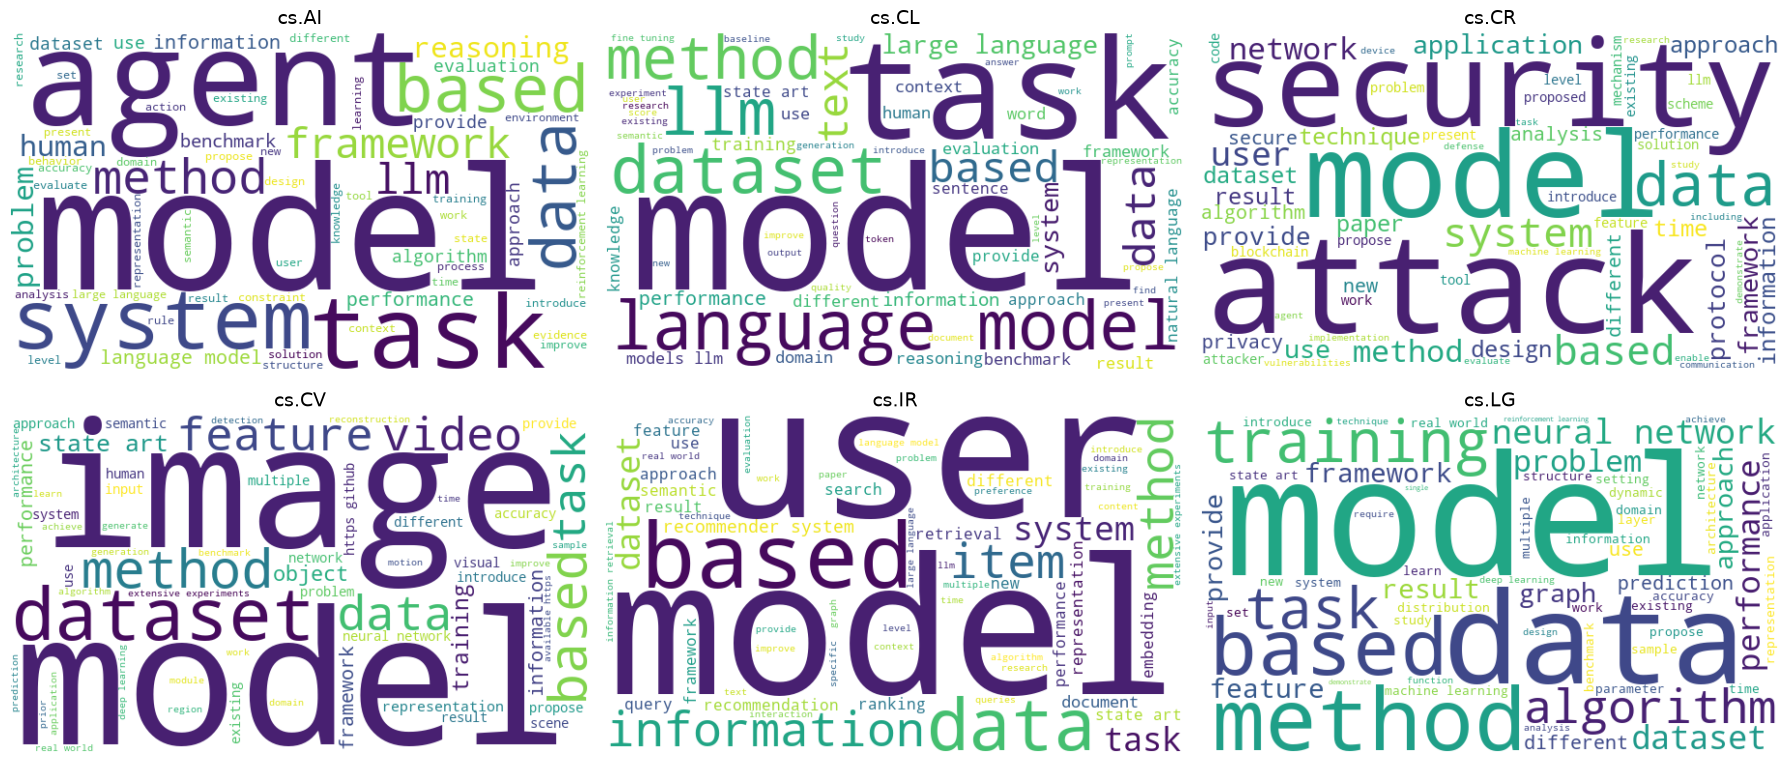

In [5]:
# One word cloud per research domain (Week 1, section 4)
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, category in zip(axes.ravel(), CATEGORIES):
    words = []
    for text in df.loc[df["primary_category"] == category, "abstract"]:
        words.extend(w for w in simple_words(text) if w not in STOP_WORDS and len(w) > 2)
    cloud = WordCloud(width=600, height=350, background_color="white", max_words=60,
                      random_state=SEED).generate(" ".join(words))
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(category, fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Week 1 text statistics are the cheapest sanity check on the data before any modelling: they show the six domains have similar abstract lengths (169–187 words) but different vocabularies, which already hints that lexical features can separate them. The word clouds give the presentation a one-glance view of each domain.


## Preprocessing pipeline

`extraction.preprocess(text)` (Week 2): clean the text (LaTeX maths, LaTeX commands, URLs, extra spaces), tokenise with spaCy, lowercase, drop stop-words, punctuation and numbers, then lemmatise. The LaTeX rules were added to the Week 2 `clean_text` because about 7% of abstracts contain `$...$` maths.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Week 2 preprocessing feeds every later component: TF-IDF features (03, 04) and the key-phrase extractor (below) all consume the cleaned, lemmatised tokens. Lemmatisation is chosen over stemming because it keeps real words (`analysis`, not `analys`) that the LLM prompts and keyword tables can show to a user; the LaTeX rules are needed because ~7% of arXiv abstracts contain `$...$` maths that would otherwise become junk tokens.


In [6]:
# One abstract that contains LaTeX, before and after each step
has_early_latex = df["abstract"].str.find("$").between(0, 250)   # a "$" in the first 250 characters
example = df[has_early_latex].iloc[0]["abstract"]
print("RAW:\n", example[:400], "\n")
print("CLEANED:\n", ex.clean_text(example)[:400], "\n")
print("TOKENS (no lemmatisation):\n", ex.preprocess(example, lemmatise=False)[:30], "\n")
print("TOKENS (lemmatised):\n", ex.preprocess(example)[:30])

RAW:
 Prompt-learning has become a new paradigm in modern natural language processing, which directly adapts pre-trained language models (PLMs) to $cloze$-style prediction, autoregressive modeling, or sequence to sequence generation, resulting in promising performances on various tasks. However, no standard implementation framework of prompt-learning is proposed yet, and most existing prompt-learning co 

CLEANED:
 Prompt-learning has become a new paradigm in modern natural language processing, which directly adapts pre-trained language models (PLMs) to -style prediction, autoregressive modeling, or sequence to sequence generation, resulting in promising performances on various tasks. However, no standard implementation framework of prompt-learning is proposed yet, and most existing prompt-learning codebases 

TOKENS (no lemmatisation):
 ['prompt', 'learning', 'new', 'paradigm', 'modern', 'natural', 'language', 'processing', 'directly', 'adapts', 'pre', 'trained', 'language', 'models',

In [7]:
# Stemming (NLTK Porter) vs lemmatisation (spaCy) on words that are common in the corpus (Week 2, section 4)
stemmer = PorterStemmer()
nlp = ex.get_nlp()
test_words = ["networks", "learning", "studies", "proposed", "better", "models",
              "trained", "datasets", "analyses", "efficiency", "generalization", "queries"]

comparison = []
for word in test_words:
    comparison.append({"word": word, "stem": stemmer.stem(word), "lemma": nlp(word)[0].lemma_})
pd.DataFrame(comparison)

,word,stem,lemma
0,networks,network,network
1,learning,learn,learn
2,studies,studi,study
3,proposed,propos,propose
4,better,better,well
5,models,model,model
6,trained,train,train
7,datasets,dataset,dataset
8,analyses,analys,analysis
9,efficiency,effici,efficiency


In [8]:
# How much each step shrinks the vocabulary, on 1,000 training abstracts (takes about 30 s)
sample_texts = train_df.sample(n=1000, random_state=SEED)["abstract"].tolist()

raw_vocab, no_stop_vocab, stem_vocab, lemma_vocab = set(), set(), set(), set()
for text in sample_texts:
    words = simple_words(text)
    raw_vocab.update(words)
    surface = ex.preprocess(text, lemmatise=False)
    no_stop_vocab.update(surface)
    stem_vocab.update(stemmer.stem(w) for w in surface)
    lemma_vocab.update(ex.preprocess(text))

vocab_reduction = pd.DataFrame({
    "step": ["raw lowercase words", "cleaned, no stop-words/punct/numbers", "+ Porter stemming", "+ spaCy lemmatisation"],
    "vocab_size": [len(raw_vocab), len(no_stop_vocab), len(stem_vocab), len(lemma_vocab)],
})
results["vocab_reduction_1000_abstracts"] = dict(zip(vocab_reduction["step"], vocab_reduction["vocab_size"]))
vocab_reduction

,step,vocab_size
0,raw lowercase words,11417
1,"cleaned, no stop-words/punct/numbers",10818
2,+ Porter stemming,6483
3,+ spaCy lemmatisation,8466


## POS-based key phrases

Week 3 POS tagging. `pos_key_phrases` keeps token runs that match the pattern `ADJ* NOUN+` (for example "masked autoencoder", "bipartite matching"); spaCy's `noun_chunks` is used as a second, parser-based way to get noun phrases. Both are run on a fixed sample of 600 test papers (about 100 per domain).

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Week 3 POS tagging turns an abstract into candidate keywords without any training data: `ADJ* NOUN+` runs capture the multi-word technical terms ("masked autoencoder") that single-word TF-IDF misses, and `noun_chunks` gives a parser-based second opinion. These phrases are what the end-to-end demo shows as the paper's topics and are the system's fallback when the LLM is unavailable.


In [9]:
analysis_df = test_df.sample(n=600, random_state=SEED).reset_index(drop=True)
docs = list(nlp.pipe([ex.clean_text(t) for t in analysis_df["abstract"]]))
print(len(docs), "abstracts parsed")

600 abstracts parsed


In [10]:
# POS tags of the first sentence of one abstract, then the phrases each method finds
doc = docs[0]
first_sentence = list(doc.sents)[0]
print(analysis_df.loc[0, "title"], "\n")
print(pd.DataFrame([(t.text, t.pos_, t.tag_) for t in first_sentence], columns=["token", "POS", "tag"]).T.to_string(header=False))
print("\nADJ* NOUN+ key phrases:", ex.pos_key_phrases(doc)[:12])
print("\nspaCy noun chunks:     ", ex.noun_chunks(doc)[:12])

The Right to be Forgotten in Federated Learning: An Efficient Realization with Rapid Retraining 

token   In  Machine  Learning      ,  the  emergence   of  the  right    to   be  forgotten  gave  birth   to    a  paradigm  named  machine  unlearning      ,  which  enables  data  holders    to  proactively  erase  their  data  from    a  trained  model      .
POS    ADP    PROPN     PROPN  PUNCT  DET       NOUN  ADP  DET   NOUN  PART  AUX       VERB  VERB   NOUN  ADP  DET      NOUN   VERB     NOUN        NOUN  PUNCT   PRON     VERB  NOUN     NOUN  PART          ADV   VERB   PRON  NOUN   ADP  DET     VERB   NOUN  PUNCT
tag     IN      NNP       NNP      ,   DT         NN   IN   DT     NN    TO   VB        VBN   VBD     NN   IN   DT        NN    VBN       NN          NN      ,    WDT      VBZ   NNS      NNS    TO           RB     VB   PRP$   NNS    IN   DT      VBN     NN      .

ADJ* NOUN+ key phrases: ['machine learning', 'machine unlearning', 'data holders', 'techniques focus', 'centr

In [11]:
# Most frequent key phrases per research domain
phrase_rows = {}
phrases_per_paper = []
chunks_per_paper = []
category_counters = {}
for category in CATEGORIES:
    counter = Counter()
    for doc, cat in zip(docs, analysis_df["primary_category"]):
        if cat == category:
            counter.update(set(ex.pos_key_phrases(doc)))      # set(): count each phrase once per paper
    category_counters[category] = counter

# A phrase in the top-25 of 3 or more domains ("extensive experiments", "experimental results")
# says nothing about the domain, so it is treated as generic and hidden from the table.
top_lists = Counter()
for counter in category_counters.values():
    top_lists.update(p for p, c in counter.most_common(25))
generic_phrases = {p for p, n in top_lists.items() if n >= 3}
print("Generic phrases removed:", sorted(generic_phrases))

for category, counter in category_counters.items():
    phrase_rows[category] = [p for p, c in counter.most_common(40) if p not in generic_phrases][:5]
for doc in docs:
    phrases_per_paper.append(len(ex.pos_key_phrases(doc)))
    chunks_per_paper.append(len(ex.noun_chunks(doc)))

results["mean_key_phrases_per_paper"] = round(float(np.mean(phrases_per_paper)), 1)
results["mean_noun_chunks_per_paper"] = round(float(np.mean(chunks_per_paper)), 1)
print("Mean key phrases per paper:", results["mean_key_phrases_per_paper"],
      "| mean noun chunks per paper:", results["mean_noun_chunks_per_paper"])
pd.DataFrame(phrase_rows)

Generic phrases removed: ['art performance', 'experimental results', 'extensive experiments', 'large language model', 'large language models', 'machine learning', 'real-world', 'reinforcement learning', 'wide range']
Mean key phrases per paper: 25.3 | mean noun chunks per paper: 27.3


,cs.AI,cs.CL,cs.CR,cs.CV,cs.IR,cs.LG
0,artificial intelligence,language models,adversarial attacks,deep learning,recommender systems,neural networks
1,multi-agent systems,natural language processing,prior work,art methods,collaborative filtering,source code
2,observable markov decision processes,better results,sensitive information,computer vision,information retrieval,competitive performance
3,optimization objective,further research,% accuracy,previous methods,real-world datasets,deep learning
4,domain knowledge,dialogue systems,recent years,benchmark datasets,large-scale,deep neural networks


## NER and regex extraction

Two non-LLM ways to find the paper's named methods and datasets:
- **spaCy NER** (Week 3): the pretrained `en_core_web_sm` entity recogniser. It was trained on news text, so it has no METHOD or DATASET label and tags most model names as ORG or PRODUCT.
- **Regex rules** (Week 3, rule-based IE): mixed-case acronyms such as `BERT`, `ImageNet-1k`, `GPT-4o` (a stop-list removes generic ones like `AI`, `LLMs`), acronym definitions "Long Form (LF)", names followed by "dataset/benchmark/corpus", plus years and percentages.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** The spec asks for NER of authors/institutions, but affiliations are absent from arXiv metadata, so NER is pointed at what the abstracts do contain: method and dataset names. spaCy's news-trained NER has no METHOD/DATASET labels, so a Week 3 rule-based extractor (mixed-case acronyms, `X dataset`, years) is run alongside it; comparing the two is a cheap, fully explainable baseline for the LLM extractor.


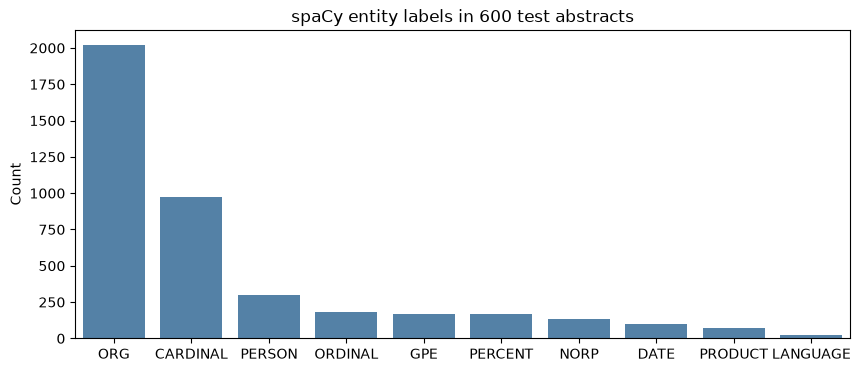

Most common ORG/PRODUCT entities: [('LLM', 55), ('NLP', 29), ('ML', 24), ('RL', 20), ('Transformer', 18), ('LoRA', 17), ('IoT', 15), ('BERT', 14), ('API', 13), ('CNN', 13), ('Large Language Models', 12), ('IP', 12), ('IR', 11), ('RowHammer', 10), ('PI', 10)]


In [12]:
# Which entity labels does spaCy assign in research abstracts?
label_counts = Counter()
org_product = Counter()
for doc in docs:
    for ent in doc.ents:
        label_counts[ent.label_] += 1
        if ent.label_ in ("ORG", "PRODUCT"):
            org_product[ent.text] += 1

results["spacy_entity_labels_600_papers"] = dict(label_counts.most_common(10))
labels, counts = zip(*label_counts.most_common(10))
plt.figure(figsize=(10, 4))
sns.barplot(x=list(labels), y=list(counts), color="steelblue")
plt.title("spaCy entity labels in 600 test abstracts")
plt.ylabel("Count")
plt.show()
print("Most common ORG/PRODUCT entities:", org_product.most_common(15))

In [13]:
# Regex extraction over the same 600 papers
acronym_counts = Counter()
n_definitions = 0
n_dataset_mentions = 0
papers_with_year = 0
for text in analysis_df["abstract"]:
    rules = ex.regex_extract(text)
    acronym_counts.update(rules["acronyms"])
    n_definitions += len(rules["definitions"])
    n_dataset_mentions += len(rules["datasets"])
    if rules["years"]:
        papers_with_year += 1

results["regex_600_papers"] = {"acronym_definitions": n_definitions,
                               "dataset_mentions": n_dataset_mentions,
                               "papers_with_a_year": papers_with_year}
print(results["regex_600_papers"])
print("Most common specific acronyms/names:", acronym_counts.most_common(20))

{'acronym_definitions': 299, 'dataset_mentions': 56, 'papers_with_a_year': 31}
Most common specific acronyms/names: [('RAG', 10), ('ImageNet', 9), ('LSTM', 7), ('BERT', 7), ('RS', 6), ('ASR', 6), ('FL', 5), ('GRPO', 5), ('LoRA', 5), ('CoT', 5), ('KG', 5), ('CIFAR-10', 5), ('ChatGPT', 5), ('CT', 4), ('SFT', 4), ('MAE', 4), ('GPT-4o', 4), ('RAM', 4), ('GLUE', 4), ('OpenClaw', 4)]


In [14]:
# Everything the basic extractors return for one paper (this is what NB06 shows in the demo)
i = 1
print(analysis_df.loc[i, "title"], "\n")
for key, value in ex.extract(analysis_df.loc[i, "abstract"]).items():
    print(f"{key:12s} {value[:8]}")

Sequential Recommendation via Stochastic Self-Attention 

key_phrases  ['sequential recommendation models', 'previous behaviors', 'next item', 'dot-product self-attention', 'superior capabilities', 'sequential methods', 'real-world', 'sequential behaviors']
noun_chunks  ['sequential recommendation models', "user's previous behaviors", 'next item', 'transformer-based approaches', 'dot-product self-attention', 'superior capabilities', 'existing sequential methods', "users' real-world sequential behaviors"]
entities     [('Sequential', 'GPE'), ('BPR', 'ORG'), ('STOchastic Self-Attention~(STOSA', 'ORG'), ('Wasserstein Self-Attention', 'PERSON'), ('Wasserstein', 'PERSON')]
acronyms     ['BPR', 'STOchastic', 'STOSA']
definitions  []
datasets     []
years        []
percentages  []


In [15]:
# Agreement between the two extractors: how many regex names does spaCy also tag as an entity?
both, regex_only = 0, 0
for doc, text in zip(docs, analysis_df["abstract"]):
    entity_texts = {ent.text for ent in doc.ents}
    for name in ex.regex_artefacts(text):
        if name in entity_texts:
            both += 1
        else:
            regex_only += 1
results["regex_names_also_found_by_spacy"] = round(both / max(both + regex_only, 1), 3)
print(f"{both} of {both + regex_only} regex names are also spaCy entities "
      f"({results['regex_names_also_found_by_spacy']:.0%})")

747 of 1352 regex names are also spaCy entities (55%)


## Few-shot LLM extraction

Advanced technique (Week 9 few-shot prompting): an instruction, three worked examples and the new abstract, asking for JSON with `methods`, `datasets` and `tasks`. The three example abstracts were written for this prompt (they are not real papers) so they cannot leak test data. The call goes through the team's shared `llm.generate` (temperature 0, cached in `artifacts/llm_cache.jsonl`).

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Few-shot prompting (Week 9) is the advanced counterpart: three worked examples teach the model the JSON schema and what counts as a method vs a dataset, with no fine-tuning data. It is expected to recover names the rules miss (lower-case or multi-word methods) at the cost of latency and occasional invented names, which the evaluation below measures.


In [16]:
import llm
print("LLM backend:", llm.describe())
print(ex.build_few_shot_prompt(analysis_df.loc[1, "abstract"])[-900:])

LLM backend: {'backend': 'hf', 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
tive items, which misleads the optimization. We propose a novel STOchastic Self-Attention~(STOSA) to overcome these issues. STOSA, in particular, embeds each item as a stochastic Gaussian distribution, the covariance of which encodes the uncertainty. We devise a novel Wasserstein Self-Attention module to characterize item-item position-wise relationships in sequences, which effectively incorporates uncertainty into model training. Wasserstein attentions also enlighten the collaborative transitivity learning as it satisfies triangle inequality. Moreover, we introduce a novel regularization term to the ranking loss, which assures the dissimilarity between positive and the negative items. Extensive experiments on five real-world benchmark datasets demonstrate the superiority of the proposed model over state-of-the-art baselines, especially on cold start items. The code is available in
JSON:


In [17]:
print(analysis_df.loc[1, "title"])
ex.llm_extract(analysis_df.loc[1, "abstract"])

Sequential Recommendation via Stochastic Self-Attention


{'methods': ['Transformer-based approaches',
  'dot-product self-attention',
  'BPR loss',
  'Wasserstein Self-Attention',
  'regularization term'],
 'datasets': ['five real-world benchmark datasets'],
 'tasks': ['sequential recommendation']}

## Evaluation on hand-labelled abstracts

20 test papers (seed 43, never seen by any prompt) are labelled in `artifacts/02_gold_labels.json`.

**Labelling guideline.** `methods` = named or clearly specific models, algorithms and techniques the paper proposes or uses ("HiRM", "symbolic execution"); `datasets` = named datasets, benchmarks and evaluation targets ("ImageNet", "VTAB", "OpenSSL"); `tasks` = the research problem ("concept erasure"). Names are copied as written; an acronym and its long form are both kept, because either is a correct answer for a user. Generic terms ("deep learning", "baseline") are not labelled.

**Scoring.** Micro P/R/F1 over `methods + datasets`, relaxed match (equal after lowercasing and removing punctuation, or one contains the other, e.g. "VOC" vs "Pascal-VOC"). Each gold name can be matched once.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Precision/recall against 20 hand-labelled abstracts is the only way to score extraction, since the dataset has no gold entities. Relaxed matching (normalised, substring) is used because the same method is written several ways in one abstract ("HiRM", "High-Level Representation Misdirection"); 20 papers is small, so the numbers are indicative and the error analysis matters as much as the table.


In [18]:
GOLD_PATH = ARTIFACTS_DIR / "02_gold_labels.json"

if not GOLD_PATH.exists():
    to_label = test_df.sample(n=20, random_state=SEED + 1)
    template = []
    for _, row in to_label.iterrows():
        template.append({"id": row["id"], "title": row["title"], "abstract": row["abstract"],
                         "methods": [], "datasets": [], "tasks": [], "labelled": False})
    GOLD_PATH.write_text(json.dumps(template, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Created", GOLD_PATH, "- label it, then re-run this section.")

gold = json.loads(GOLD_PATH.read_text(encoding="utf-8"))
labelled = [g for g in gold if g["labelled"]]
print(f"{len(labelled)} of {len(gold)} abstracts labelled")

20 of 20 abstracts labelled


In [19]:
def score(extractor_name, predict, fields=("methods", "datasets")):
    """Micro P/R/F1 of one extractor over all labelled abstracts."""
    tp_total, pred_total, gold_total = 0, 0, 0
    for item in labelled:
        gold_names = [name for field in fields for name in item[field]]
        tp, n_pred, n_gold = ex.match_counts(predict(item), gold_names)
        tp_total += tp
        pred_total += n_pred
        gold_total += n_gold
    p, r, f1 = ex.precision_recall_f1(tp_total, pred_total, gold_total)
    return {"extractor": extractor_name, "precision": p, "recall": r, "f1": f1,
            "predicted": pred_total, "gold": gold_total}


def names(output):
    return output["methods"] + output["datasets"]


# 2 x 20 LLM calls (zero-shot and few-shot), cached in artifacts/llm_cache.jsonl
few_raw = {item["id"]: ex.llm_extract(item["abstract"], shots=3, return_raw=True) for item in labelled}
zero_raw = {item["id"]: ex.llm_extract(item["abstract"], shots=0, return_raw=True) for item in labelled}
few = {k: v[0] for k, v in few_raw.items()}
zero = {k: v[0] for k, v in zero_raw.items()}

extraction_scores = pd.DataFrame([
    score("Regex rules (W3)", lambda item: ex.regex_artefacts(item["abstract"])),
    score("spaCy NER ORG/PRODUCT (W3)", lambda item: ex.spacy_artefacts(item["abstract"])),
    score("Zero-shot LLM (W9)", lambda item: names(zero[item["id"]])),
    score("Few-shot LLM (W9)", lambda item: names(few[item["id"]])),
    score("Hybrid: few-shot LLM + regex", lambda item: ex.hybrid_artefacts(names(few[item["id"]]), item["abstract"])),
])
results["llm_backend"] = llm.describe()
results["n_labelled_abstracts"] = len(labelled)
results["extraction_scores"] = extraction_scores.to_dict(orient="records")
display(extraction_scores)


W1028 15:22:06.085000 23720 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,extractor,precision,recall,f1,predicted,gold
0,Regex rules (W3),0.780,0.356,0.489,41,90
1,spaCy NER ORG/PRODUCT (W3),0.643,0.300,0.409,42,90
2,Zero-shot LLM (W9),0.880,0.244,0.383,25,90
3,Few-shot LLM (W9),0.708,0.567,0.630,72,90
4,Hybrid: few-shot LLM + regex,0.698,0.667,0.682,86,90


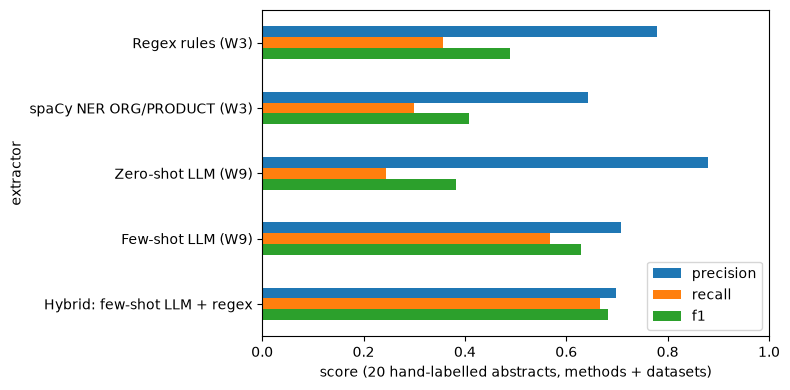

In [20]:
# Same table as a chart for the slides
ax = extraction_scores.set_index("extractor")[["precision", "recall", "f1"]].plot.barh(figsize=(8, 4))
ax.set_xlim(0, 1)
ax.set_xlabel("score (20 hand-labelled abstracts, methods + datasets)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "02_extraction_scores.png", dpi=150)
plt.show()


**Per field and format check.** Only the LLM separates methods, datasets and tasks, so per-field scores are reported for the two prompts. Two W10-style reliability checks: the share of replies that are valid JSON, and the share of returned names that actually occur in the abstract (a name that does not occur was invented or paraphrased).

In [21]:
per_field_rows = []
for prompt_name, outputs in [("zero-shot", zero), ("few-shot", few)]:
    for field in ["methods", "datasets", "tasks"]:
        row = score(prompt_name, lambda item, f=field: outputs[item["id"]][f], fields=(field,))
        row["field"] = field
        per_field_rows.append(row)
per_field = pd.DataFrame(per_field_rows)[["extractor", "field", "precision", "recall", "f1", "predicted", "gold"]]
display(per_field)

reliability_rows = []
for prompt_name, raw in [("zero-shot", zero_raw), ("few-shot", few_raw)]:
    valid = [ex.is_valid_json_answer(reply) for _, reply in raw.values()]
    all_names, in_abstract = 0, 0
    for item in labelled:
        returned = [n for n in names(raw[item["id"]][0]) + raw[item["id"]][0]["tasks"] if ex.normalise(n)]
        all_names += len(returned)
        in_abstract += sum(ex.grounded(n, item["abstract"]) for n in returned)
    reliability_rows.append({"prompt": prompt_name,
                             "valid_json_rate": round(sum(valid) / len(valid), 3),
                             "names_returned": all_names,
                             "names_found_in_abstract": round(in_abstract / max(all_names, 1), 3)})
reliability = pd.DataFrame(reliability_rows)
display(reliability)

results["llm_per_field"] = per_field.to_dict(orient="records")
results["llm_reliability"] = reliability.to_dict(orient="records")


,extractor,field,precision,recall,f1,predicted,gold
0,zero-shot,methods,0.875,0.296,0.442,24,71
1,zero-shot,datasets,1.000,0.053,0.100,1,19
2,zero-shot,tasks,0.593,0.348,0.438,27,46
3,few-shot,methods,0.725,0.521,0.607,51,71
4,few-shot,datasets,0.667,0.737,0.700,21,19
5,few-shot,tasks,0.500,0.217,0.303,20,46


,prompt,valid_json_rate,names_returned,names_found_in_abstract
0,zero-shot,1.0,52,0.962
1,few-shot,1.0,92,0.891


**Error analysis.** For every gold name an extractor misses, check whether it is written in lower case only ("symbolic execution"). Rules look for capital letters, so they should miss these; the LLM should not. False positives are listed so the typical mistakes can be named.

In [22]:
def misses(predict):
    """Gold names an extractor did not find, split into lower-case-only vs capitalised names."""
    lower, capital = [], []
    for item in labelled:
        predicted = predict(item)
        for gold_name in item["methods"] + item["datasets"]:
            tp, _, _ = ex.match_counts(predicted, [gold_name])
            if tp == 0:
                (lower if gold_name == gold_name.lower() else capital).append(gold_name)
    return lower, capital


def false_positives(predict):
    wrong = []
    for item in labelled:
        gold_names = item["methods"] + item["datasets"]
        for name in predict(item):
            tp, _, _ = ex.match_counts([name], gold_names)
            if tp == 0:
                wrong.append(name)
    return wrong


all_gold = [g for item in labelled for g in item["methods"] + item["datasets"]]
n_lower_gold = sum(g == g.lower() for g in all_gold)
error_rows = []
for name, predict in [("Regex rules", lambda item: ex.regex_artefacts(item["abstract"])),
                      ("Few-shot LLM", lambda item: names(few[item["id"]])),
                      ("Hybrid", lambda item: ex.hybrid_artefacts(names(few[item["id"]]), item["abstract"]))]:
    lower, capital = misses(predict)
    fps = false_positives(predict)
    error_rows.append({"extractor": name,
                       "missed lower-case names": f"{len(lower)} / {n_lower_gold}",
                       "missed capitalised names": f"{len(capital)} / {len(all_gold) - n_lower_gold}",
                       "false positives": len(fps),
                       "example false positives": ", ".join(fps[:6])})
error_analysis = pd.DataFrame(error_rows)
results["error_analysis"] = error_analysis.to_dict(orient="records")
display(error_analysis)


,extractor,missed lower-case names,missed capitalised names,false positives,example false positives
0,Regex rules,32 / 32,26 / 58,8,"T2I, CIR, CBRN, NP, EM, PTLM"
1,Few-shot LLM,18 / 32,17 / 58,20,submodular maximization with cardinality const...
2,Hybrid,18 / 32,8 / 58,25,submodular maximization with cardinality const...


In [23]:
# One labelled paper, gold vs each extractor (used on the slide)
item = next(it for it in labelled if it["id"] == "2602.19631")   # HiRM concept-erasure paper
print(item["title"], "\n")
print("GOLD     :", item["methods"] + item["datasets"])
print("REGEX    :", ex.regex_artefacts(item["abstract"]))
print("SPACY    :", ex.spacy_artefacts(item["abstract"]))
print("ZERO-SHOT:", names(zero[item["id"]]))
print("FEW-SHOT :", names(few[item["id"]]))
print("HYBRID   :", ex.hybrid_artefacts(names(few[item["id"]]), item["abstract"]))


Localized Concept Erasure in Text-to-Image Diffusion Models via High-Level Representation Misdirection 

GOLD     : ['High-Level Representation Misdirection', 'HiRM', 'U-Net', 'Flux', 'causal tracing', 'UnlearnCanvas', 'NSFW benchmarks']
REGEX    : ['T2I', 'HiRM', 'UnlearnCanvas', 'NSFW']
SPACY    : ['U-Net', 'High-Level Representation Misdirection', 'HiRM', 'UnlearnCanvas', 'NSFW']
ZERO-SHOT: ['High-Level Representation Misdirection (HiRM)', 'Fine-tuning']
FEW-SHOT : ['text-to-image (T2I) diffusion models', 'concept erasure techniques', 'fine-tuning the denoising component', 'causal tracing studies', 'High-Level Representation Misdirection (HiRM)', 'decoupling strategy', 'UnlearnCanvas', 'NSFW']
HYBRID   : ['text-to-image (T2I) diffusion models', 'concept erasure techniques', 'fine-tuning the denoising component', 'causal tracing studies', 'High-Level Representation Misdirection (HiRM)', 'decoupling strategy', 'UnlearnCanvas', 'NSFW']


## Findings and limitations

<!-- fill the ▢ values from the tables above after the final run -->
- **Preprocessing.** Lemmatisation keeps 8,466 word types vs 6,483 for Porter stemming on 1,000 abstracts: stemming merges more, but into non-words (`analys`), so lemmas are used because they are shown to users and fed to TF-IDF in NB03/NB04.
- **Basic extractors.** Regex rules are precise (P = 0.78) but find only about a third of the gold names (R = 0.36): every lower-case method ("symbolic execution", "itemset mining") is invisible to a capital-letter rule. spaCy NER has no METHOD/DATASET label, so it only catches names it happens to tag ORG/PRODUCT, and scores below the rules.
- **LLM.** Few-shot prompting reaches F1 = ▢ vs ▢ zero-shot; the worked examples mostly fix the *format* (valid JSON ▢ → ▢) and the method/dataset boundary. ▢% of returned names do not occur in the abstract, so the output still needs the grounding check. The hybrid adds the rules' acronyms and gives the best recall (▢), so it is the extractor recommended for the NB06 demo.
- **Limitations.** 20 abstracts and one annotator (labels drafted with AI help, then checked), so differences of a few points are within noise; relaxed substring matching is lenient ("GDK" matches "Linux GDK"); a 1.5B model was used for cost, and the arXiv metadata has no affiliations, so the spec's author/institution NER is limited to the `author_list` field.
- **Improvements.** Label 50+ abstracts with two annotators and report agreement; constrain the LLM to spans copied from the abstract (drop names that fail `ex.grounded`); try a larger model or SciBERT-based NER trained on SciERC.

In [24]:
path = save_results("02", results)
print("Saved", path.relative_to(ARTIFACTS_DIR.parent))
results

Saved artifacts/02_results.json


{'corpus_stats': [{'category': 'cs.AI',
   'papers': 2000,
   'mean_words': 178.8,
   'vocab_size': 15258,
   'type_token_ratio': 0.0427},
  {'category': 'cs.CL',
   'papers': 2000,
   'mean_words': 168.6,
   'vocab_size': 13824,
   'type_token_ratio': 0.041},
  {'category': 'cs.CR',
   'papers': 2000,
   'mean_words': 181.8,
   'vocab_size': 15245,
   'type_token_ratio': 0.0419},
  {'category': 'cs.CV',
   'papers': 2000,
   'mean_words': 187.2,
   'vocab_size': 14714,
   'type_token_ratio': 0.0393},
  {'category': 'cs.IR',
   'papers': 2000,
   'mean_words': 184.8,
   'vocab_size': 13308,
   'type_token_ratio': 0.036},
  {'category': 'cs.LG',
   'papers': 2000,
   'mean_words': 182.6,
   'vocab_size': 14251,
   'type_token_ratio': 0.039}],
 'vocab_reduction_1000_abstracts': {'raw lowercase words': 11417,
  'cleaned, no stop-words/punct/numbers': 10818,
  '+ Porter stemming': 6483,
  '+ spaCy lemmatisation': 8466},
 'mean_key_phrases_per_paper': 25.3,
 'mean_noun_chunks_per_paper': 27